# Solutions · 06 · Absorption and stripping

Worked solutions to the exercises of [notebook 06](../notebooks/06_absorption_and_stripping.ipynb). Try each exercise
yourself before reading its solution - the learning happens in the attempt. Solutions are one way to
answer each question; other correct approaches exist.

In [1]:
try:                      # on Google Colab (or anywhere engsep is missing): install it from GitHub
    import engsep
except ImportError:
    import subprocess, sys
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "git+https://github.com/ktwyw/engsep"], check=True)
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from engsep import absorption as ab
plt.rcParams.update({"figure.figsize": (7, 4), "figure.dpi": 90, "axes.grid": True, "grid.alpha": 0.3,
                     "axes.spines.top": False, "axes.spines.right": False})

import inspect
from IPython.display import Code

def show_source(obj):
    """Display the source code of a library function or class."""
    return Code(inspect.getsource(obj), language="python")

def heading(text):
    print(f"\n{text}\n" + "=" * len(text))

## Exercise 1

An absorber must remove 99 % of the SO2 (1.5 mol %) from 200 kmol/h of flue gas with water at 1 atm (m = 40 at 25 degC). Find L_min, the stages at 1.5 L_min, and then repeat at 10 degC (m = 25) and 40 degC (m = 70). Why do scrubbers run cold?

In [2]:
V, y_in, rec = 200.0, 0.015, 0.99
y_out = y_in * (1 - rec)
for T_C, m in ((10, 25.0), (25, 40.0), (40, 70.0)):
    L_min = ab.minimum_solvent(V, y_in, y_out, m)
    L = 1.5 * L_min
    A = ab.absorption_factor(L, V, m)
    print(f"{T_C} degC (m = {m}): L_min = {L_min:.0f} kmol/h, at 1.5 L_min = {L:.0f} kmol/h: A = {A:.2f}, stages = {ab.kremser_stages(A, rec):.1f}")

10 degC (m = 25.0): L_min = 4950 kmol/h, at 1.5 L_min = 7425 kmol/h: A = 1.49, stages = 8.9
25 degC (m = 40.0): L_min = 7920 kmol/h, at 1.5 L_min = 11880 kmol/h: A = 1.48, stages = 8.9
40 degC (m = 70.0): L_min = 13860 kmol/h, at 1.5 L_min = 20790 kmol/h: A = 1.49, stages = 8.9


SO$_2$ is a poorly soluble gas in water ($m$ = 40): even 99 % removal needs a solvent flow forty times the gas
flow, and warming the water to 40 degC nearly doubles it. Solubility falls with temperature, so scrubbers run
cold - or, as most SO$_2$ scrubbers do, with an alkaline liquor that reacts with the gas and slashes the
effective $m$.

## Exercise 2

The rich solvent (x = 0.01) is stripped with air. Plot the stages needed against the stripping factor from 1.2 to 5 for 95 and 99 % stripping. Where does adding stripping gas stop paying?

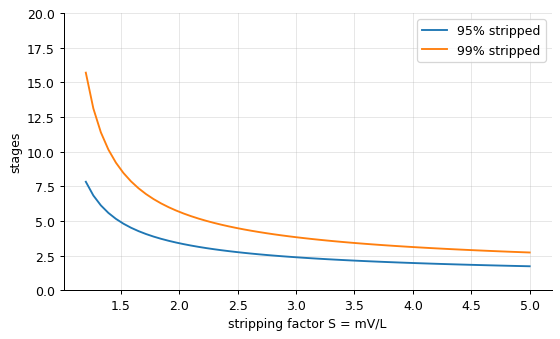

stages at S = 1.5 / 2 / 3 / 5 for 99 %: [8.7, 5.7, 3.8, 2.7]


In [3]:
Ss = np.linspace(1.2, 5, 60)
fig, ax = plt.subplots()
for phi in (0.95, 0.99):
    ax.plot(Ss, [ab.kremser_stages(S, phi) for S in Ss], label=f"{phi:.0%} stripped")
ax.set(xlabel="stripping factor S = mV/L", ylabel="stages", ylim=(0, 20)); ax.legend(); plt.show()
print("stages at S = 1.5 / 2 / 3 / 5 for 99 %:", [round(ab.kremser_stages(S, 0.99), 1) for S in (1.5, 2, 3, 5)])

The stage count falls steeply up to a stripping factor of about 2 and flattens beyond 3: more stripping gas
then buys little and costs compression or steam. The knee of the Kremser curve, at $S$ (or $A$) between 1.5
and 2.5, is where absorbers and strippers are designed.

## Exercise 3

**Implement it yourself:** write a stage-by-stage absorber (equilibrium, then operating line) for a linear equilibrium and reproduce the Kremser stage count for A = 1.4 and 95 % recovery.

In [4]:
m, A, rec = 0.8, 1.4, 0.95
L_over_V = A * m
y_in = 0.02; y_out = y_in * (1 - rec)
x, y, n = 0.0, y_out, 0
while y < y_in - 1e-12:
    x = y / m                                                          # liquid leaving stage n, in equilibrium with the gas leaving it
    y = y_out + L_over_V * x                                           # gas entering stage n from below (operating line)
    n += 1
print(f"stage by stage: {n} stages reach y_in (the last overshoots); Kremser: {ab.kremser_stages(A, rec):.2f}")

stage by stage: 6 stages reach y_in (the last overshoots); Kremser: 5.53


Two lines per stage - equilibrium, then operating line - step from the lean end until the rich gas is
reached; the count rounds up the Kremser value.